# Testing Attention Heads on XOR Task
The purpose of this notebook is to train linear and nonlinear attention heads on the XOR task and the extended XOR task (where the number of values is not 2, true and false).

## Imports

In [1]:
import torch
from torch.utils.data import DataLoader
import torch.nn as nn

import matplotlib.pyplot as plt

from relational_attention.tasks import XORDataset
from relational_attention.models import SelfAttentionHead, RelationalAttentionHead, AttentionClassifier
from relational_attention.training import train_model

In [2]:
torch.manual_seed(42)

## Initialize and train models on XOR task

### Initialize task

In [3]:
# Parameters
num_samples = 1000
num_vectors=2
vector_len=2
head_dim=1

In [4]:
dataset = XORDataset(
    num_samples=num_samples,
    num_vectors=num_vectors,
    vector_len=vector_len,
)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

### Initialize models

In [5]:
# Self attention head with softmax
model_self_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead
)

# Linear self attention head
model_linear_self = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead, linear=True
)

# Relational attention head with softmax
model_relat_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead
)

# Linear relational attention head
model_linear_relat = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead, linear=True
)

### Train models on XOR task

In [6]:
lr = 1e-4
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 1000

In [7]:
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=lr)
loss_self_attn = train_model(model_self_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:21<00:00, 46.10it/s, loss=0.4708]


In [8]:
optimizer = torch.optim.Adam(model_linear_self.parameters(), lr=lr)
loss_linear_self = train_model(model_linear_self, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:19<00:00, 50.51it/s, loss=0.0000]


In [9]:
optimizer = torch.optim.Adam(model_relat_attn.parameters(), lr=lr)
loss_relat_attn = train_model(model_relat_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:22<00:00, 45.12it/s, loss=0.0000]


In [10]:
optimizer = torch.optim.Adam(model_linear_relat.parameters(), lr=lr)
loss_linear_relat = train_model(model_linear_relat, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:20<00:00, 49.41it/s, loss=0.0000]


### Plot training dynamics

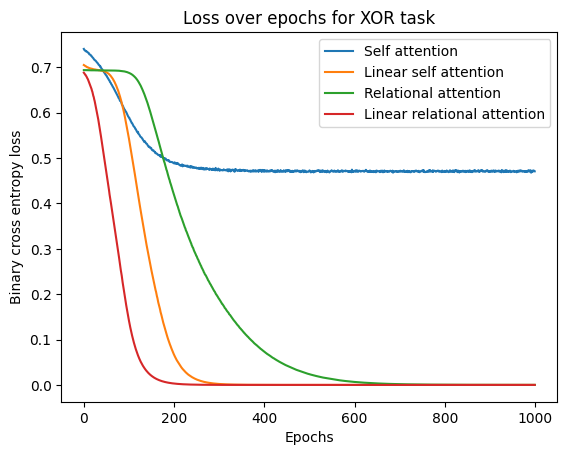

In [11]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_linear_self, label='Linear self attention')
plt.plot(loss_relat_attn, label='Relational attention')
plt.plot(loss_linear_relat, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for XOR task')
plt.legend()
plt.show()

- Would be useful to see the norm of the gradient updates
- Play around with the temperature parameter
- Add residual term

### Save model

In [12]:
metadata = {
    "embed_dim": vector_len,
    "head_dim": head_dim,
    "context_size": num_vectors,
    "pooling": "flatten",
    "num_epochs": epochs,
    "train_loss_curve": loss_linear_relat,  # if available
}

torch.save({
    "model_state": model_linear_relat.state_dict(),
    "metadata": metadata,
}, "../../data/linear_relational_attention_xor_full.pt")

## Initialize and train models on extended XOR task

### Initialize task

In [13]:
# Parameters
num_samples = 1000
num_vectors = 5
vector_len = 10
head_dim = 1

In [14]:
dataset = XORDataset(
    num_samples=num_samples,
    num_vectors=num_vectors,
    vector_len=vector_len,
)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

### Initialize models

In [15]:
# Self attention head with softmax
model_self_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead
)

# Linear self attention head
model_linear_self = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead, linear=True
)

# Relational attention head with softmax
model_relat_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead
)

# Linear relational attention head
model_linear_relat = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead, linear=True
)

## Train models on extended XOR task

In [16]:
lr = 1e-4
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 1000

In [17]:
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=lr)
loss_self_attn = train_model(model_self_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:21<00:00, 45.58it/s, loss=0.3900]


In [18]:
optimizer = torch.optim.Adam(model_linear_self.parameters(), lr=lr)
loss_linear_self = train_model(model_linear_self, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:19<00:00, 50.96it/s, loss=0.0064]


In [19]:
optimizer = torch.optim.Adam(model_relat_attn.parameters(), lr=lr)
loss_relat_attn = train_model(model_relat_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:22<00:00, 45.26it/s, loss=0.3222]


In [20]:
optimizer = torch.optim.Adam(model_linear_relat.parameters(), lr=lr)
loss_linear_relat = train_model(model_linear_relat, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 1000/1000 [00:19<00:00, 51.17it/s, loss=0.0231]


### Plot training dynamics

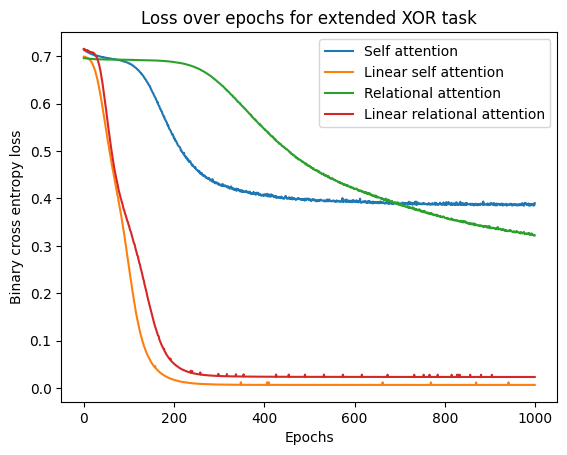

In [21]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_linear_self, label='Linear self attention')
plt.plot(loss_relat_attn, label='Relational attention')
plt.plot(loss_linear_relat, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for extended XOR task')
plt.legend()
plt.show()